# Projektni zadatak - Marica Popović RA167/2022
## Digitalna obrada signala i primena filtera

### 1. Uvod i opis signala
Signal koji se analizira u ovom projektu je audio snimak ljudskog govora (vlastiti glas), zabeležen u realnim uslovima u zašumljenom okruženju. Snimak traje približno 8 sekundi. Format signala će biti konvertovan iz izvornog oblika .m4a u .waw format.
Ljudski govor je i te kako složen talas. Važno je napomenuti da u bilo kom načinu snimanja zvuka imamo prisutne razne šumove, koji, ukoliko su veoma jaki, mogu u potpunosti izobličiti i potisnuti koristan signal. Zadatak koji imam jeste da maksimalno otklonim šum i sačuvam koristan signal.

**Priroda šuma**

Glas je snimljen u realnom okruženju i prisutni su sledeći šumovi: 
1) Šuštanje kese (visokofrekventni šum)
2) Zvuk elektronskog uređaja (niskofrekventni šum)
3) Piskav, konstantan ton (tonska smetnja od 1000Hz).

#### Analiza šumova
Niskofrekventni šum potiče od brujanja/zujanja elektronskih uređaja u pozadini koje je tiho i konstantno.  
Visokofrekventni šum je rezultat šuštanja kese, što se u spektru manifestuje kao širokopojasni šum na visokim frekvencijama.  
Tonska smetnja predstavlja konstantan, piskav ton koji se javlja usled nekih nepredviđenih okolnosti, kvara potencijalne opreme i slično.

#### Ideja
Ljudski govor obuhvata frekvencije od 300Hz do 4000Hz. Ideja jeste da konstantan piskav ton otklonim uz pomoć Notch filtera. On će precizno otkloniti šum, a glas će ostati nepromenjen. Sledeći korak jeste uklanjanje niskih i visokih frekvencija šuma pomoću propusnika opsega.  
Primeniću i IIR i FIR filtere kako bih uporedila rezultate i videla koji filter će se najbolje pokazati.   


---

#### Importovanje biblioteka i učitavanje funkcija sa vežbi

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import freqz, butter, buttord, cheby2, cheb2ord, firwin, lfilter, iirnotch

# --- 1. POMOĆNE FUNKCIJE

def zplane(zeros, poles, ax):
    Omega = np.linspace(0, 2*np.pi, 360)
    ax.plot(np.cos(Omega), np.sin(Omega), 'k--', linewidth=0.8, alpha=0.5)
    ax.axhline(0, color='k', linewidth=0.5)
    ax.axvline(0, color='k', linewidth=0.5)
    ax.plot(np.real(zeros), np.imag(zeros), 'o', color='royalblue', label='Nule')
    ax.plot(np.real(poles), np.imag(poles), 'x', color='crimson', label='Polovi')
    ax.set_title("Položaj nula i polova")
    ax.set_xlabel('Re(z)')
    ax.set_ylabel('Im(z)')
    ax.grid(True, alpha=0.3)

def plot_freqz_custom(num, den, fs, axes):
    w, H = freqz(num, den, fs=fs)
    H_norm = np.abs(H) / np.max(np.abs(H))
    H_dB = 20 * np.log10(H_norm + 1e-10)
    
    axes[0].plot(w, H_norm, color='royalblue', linewidth=2)
    axes[0].set_title("Amplitudska frek. karakteristika")
    axes[0].set_xlabel("f [Hz]")
    axes[0].set_ylabel(r"$|H(f)|$")
    axes[0].grid()

    axes[1].plot(w, H_dB, color='darkorange', linewidth=2)
    axes[1].set_title("Amplitudska frek. karakteristika (dB)")
    axes[1].set_xlabel("f [Hz]")
    axes[1].set_ylabel(r"$H(f)_{dB}$")
    axes[1].grid()

    try:
        phase = np.degrees(np.unwrap(np.angle(H)))
        axes[2].plot(w, phase, color='seagreen')
        axes[2].set_title('Fazna karakteristika')
        axes[2].set_xlabel(r'$f$ [Hz]')
        axes[2].set_ylabel(r'$\angle H(f)$ [deg]')
        axes[2].grid(alpha=0.4)
    except Exception as e:
        pass
    
    return w, H_norm

#### Učitavanje i prikaz signala u vremenskom domenu
U ovoj ćeliji vršim učitavanje .wav fajla i normalizaciju amplitude. Važna napomena je da sam prilikom konvertovanja signala u željeni format podesila da signal bude *mono* (to znači da uzimam jedan kanal) i da je frekvencija 44100Hz (audio sample rate). Normalizacija je ključna kako bi se osiguralo da su vrednosti signala u opsegu od -1 do 1, što sprečava numeričke probleme prilikom filtriranja.

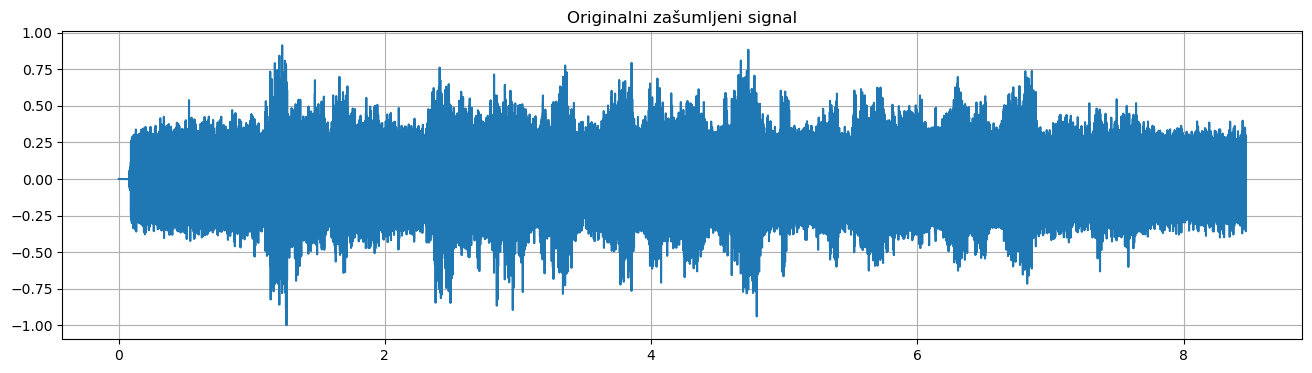

In [2]:
fs, x = wavfile.read('ProjekatDSP.wav')
x = x / np.max(np.abs(x))
vreme = np.arange(len(x)) / fs

plt.figure(figsize=(16, 4))
plt.plot(vreme, x)
plt.title('Originalni zašumljeni signal')
plt.grid()

###  2. Spektralna analiza originalnog signala  


Furijeova transformacija razlaže složen vremenski signal na sumu sinusoida različitih frekvencija. Posmatram amplitudski spektar kako bih videla količinu energije na svakoj frekvenciji. U ovoj analizi koristimo decibelsku (dB) skalu za amplitudu, jer ljudsko uho čuje logaritamski, što omogućava da lakše uočim i tiše šumove i jake pikove istovremeno.

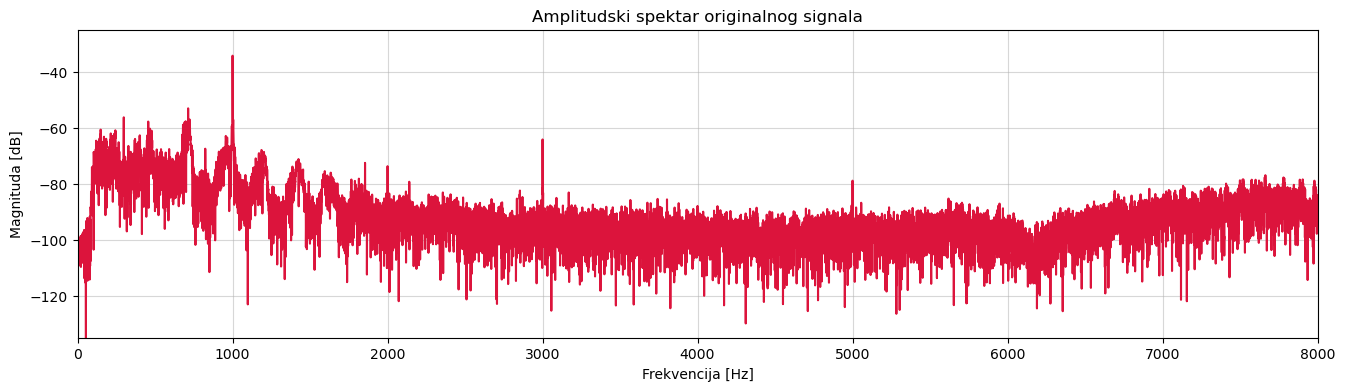

In [3]:
# --- 2.1. IZRAČUNAVANJE SPEKTRA 
N_fft = 2**16 # Broj tačaka za FFT (obično stepen dvojke radi brzine)
X_fft = np.fft.fft(x, N_fft) # Izračunavanje FFT-a
X_shifted = np.fft.fftshift(X_fft) # Centriranje spektra (0 Hz u sredini)
f_osa = np.linspace(-fs/2, fs/2, N_fft) # Kreiranje frekvencijske ose od -fs/2 do fs/2
# Magnituda spektra normalizovana i pretvorena u dB
# Delimo sa len(x) radi normalizacije energije, dodajemo 1e-10 da izbegnemo log(0)
X_mag_db = 20 * np.log10(np.abs(X_shifted) / len(x) + 1e-10)

plt.figure(figsize=(16, 4))
plt.plot(f_osa, X_mag_db, color='crimson')

# Fokusiram se na pozitivan deo spektra koji je informativan za audio [0, 8000Hz]
plt.xlim(0, 8000) 
plt.ylim(-135, -25) 

plt.title('Amplitudski spektar originalnog signala')
plt.xlabel('Frekvencija [Hz]')
plt.ylabel('Magnituda [dB]')
plt.grid(alpha=0.5)

plt.show()

#### Šta možemo primetiti?
Na prvom grafiku, pre same spektralne analize primećujemo da signal traje oko 8 sekundi i da vidimo jasne "izbočine", tj. dominantne komponente, no međutim, takođe primećujemo da pre samog govora, do 1s imamo jako puno šuma koji, kada poslušamo sam signal, zapravo i čujemo.  
U opsegu govora primećujem da energija nije konstantna već ima talasast oblik, što je odlika vokala.   
Na drugom grafiku primećujem jedan veoma jasan i ošstar pik na 1000Hz koji štrči od nivoa glasa za 20-30dB. U opsegu od 0 do 300Hz primećujem dosta energije koja potiče od korisnog signala i niskofrekventnog šuma. Frekvencije iznad 4000Hz su visokofrekventni šum i u normalnim uslovima bi trebale da opadaju, međutim u mom slučaju rastu. To se dešava jer je koristan signal zašumljen šumom od šuštanja kese koji se nalazi upravo na tim visokim frekvencijama. Takođe, pored šuma, visoke frekvencije opisuju glasove poput S, Š, T, Z.   
Ovaj spektar nam potvrđuje da je signal jako zagađen. Visokofrekventni šum je opasan jer je širokopojasan - on zauzima ceo spektar iznad 4 kHz i čini snimak prljavim.

#### Funkcije za prikaz rezultata

In [4]:
def kompletna_analiza(b, a, y, naslov):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    
    # 1. Položaj nula i polova 
    if len(a) == 1: # FIR case jer je kod njih imenilac samo jedan broj pa je len(a)=1
        b_clean = np.trim_zeros(b) 
        zeros = np.roots(b_clean)
        poles = np.zeros(len(b_clean) - 1)
        zplane(zeros, poles, axes[0, 0])
    else: # IIR case
        zplane(np.roots(b), np.roots(a), axes[0, 0])
    
    axes[0, 0].set_xlim(-1.2, 1.2)
    axes[0, 0].set_ylim(-1.2, 1.2)
    
    # 2. Amplitudska karakteristika (dB) 
    w, H = freqz(b, a, fs=fs)
    axes[0, 1].plot(w, 20*np.log10(np.abs(H) + 1e-10), color='darkorange')
    axes[0, 1].set_title("Frekvencijski odziv filtra (dB)")
    axes[0, 1].set_ylabel("Slabljenje [dB]")
    axes[0, 1].set_xlabel("f [Hz]")
    axes[0, 1].set_xlim(0, 8000)
    axes[0, 1].set_ylim(-100, 5)
    axes[0, 1].grid()

    # 3. Vremenski domen (Prikaz od 3. sekunde snimka)
    # 3. sekunda je najsigurnija za glas
    pocetak_prikaza = int(3 * fs) 
    kraj_prikaza = pocetak_prikaza + int(0.05 * fs) # Prikazujem 50ms
    
    axes[1, 0].plot(vreme[pocetak_prikaza:kraj_prikaza], x[pocetak_prikaza:kraj_prikaza], label='Original', alpha=0.5)
    axes[1, 0].plot(vreme[pocetak_prikaza:kraj_prikaza], y[pocetak_prikaza:kraj_prikaza], label='Filtrirano', color='royalblue')
    axes[1, 0].set_title("Vremenski domen (isečak glasa)")
    axes[1, 0].set_xlabel("t [s]")
    axes[1, 0].legend()
    axes[1, 0].grid(alpha=0.3)

    # 4. Spektar FILTRIRANOG signala 
    # Analiziram ceo signal
    Y = np.fft.fftshift(np.fft.fft(y, N_fft))
    Y_mag = np.abs(Y) / N_fft
    axes[1, 1].plot(f_osa, 20*np.log10(Y_mag + 1e-10), color='crimson')
    axes[1, 1].set_title("Spektar filtriranog signala (dB)")
    axes[1, 1].set_xlabel("f [Hz]")
    axes[1, 1].set_xlim(0, 5000) # Fokus na bitne frekvencije
    axes[1, 1].set_ylim(-130, -35) 
    axes[1, 1].grid()

    plt.suptitle(naslov, fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

def prikaz_vezba_stil(x, y, fs, naslov):
    # 1. DEFINISANJE ISEČKA (Uzimamo 3. sekundu gde sigurno ima glasa)
    N_fft_prikaz = 1024 # Malo veći prozor za bolju rezoluciju spektra
    pocetak = int(3 * fs) 
    
    x_isecak = x[pocetak : pocetak + N_fft_prikaz]
    y_isecak = y[pocetak : pocetak + N_fft_prikaz]
    
    # Skaliranje izlaza radi poređenja
    y_isecak_norm = y_isecak / (np.max(np.abs(y_isecak)) + 1e-10) * np.max(np.abs(x_isecak))
    
    # Vremenska osa za grafike (samo za onoliko tačaka koliko prikazujemo)
    n_stems = 100 
    t_stems = np.arange(n_stems) / fs

    # 2. IZRAČUNAVANJE SPEKTRA
    f_k = np.linspace(-fs/2, fs/2, N_fft_prikaz)
    X_fft = np.fft.fftshift(np.fft.fft(x_isecak, N_fft_prikaz))
    Y_fft = np.fft.fftshift(np.fft.fft(y_isecak_norm, N_fft_prikaz))

    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    
    # --- GORNJI RED: VREMENSKI DOMEN
    # Ulazni signal (Plava C0)
    axes[0, 0].stem(t_stems, x_isecak[:n_stems], linefmt='C0-', markerfmt='C0o', basefmt='k-')
    axes[0, 0].set_title('Ulazni signal (vremenski domen)')
    axes[0, 0].set_xlabel('t[s]')
    axes[0, 0].grid(alpha=0.3)

    # Izlazni signal (Narandžasta C1)
    axes[0, 1].stem(t_stems, y_isecak_norm[:n_stems], linefmt='C1-', markerfmt='C1o', basefmt='k-')
    axes[0, 1].set_title('Izlazni signal (vremenski domen)')
    axes[0, 1].set_xlabel('t[s]')
    axes[0, 1].grid(alpha=0.3)

    # --- DONJI RED: FREKVENCIJSKI DOMEN
    # Spektar ulaznog signala
    axes[1, 0].stem(f_k, np.abs(X_fft), linefmt='C0-', markerfmt='C0o', basefmt='k-')
    axes[1, 0].set_title('Spektar ulaznog signala')
    axes[1, 0].set_xlabel('f[Hz]')
    axes[1, 0].set_xlim(-4000, 4000) # Ograničavamo da se vide detalji glasa
    axes[1, 0].grid(alpha=0.3)

    # Spektar izlaznog signala
    axes[1, 1].stem(f_k, np.abs(Y_fft), linefmt='C1-', markerfmt='C1o', basefmt='k-')
    axes[1, 1].set_title('Spektar izlaznog signala')
    axes[1, 1].set_xlabel('f[Hz]')
    axes[1, 1].set_xlim(-4000, 4000) # Isti opseg
    axes[1, 1].grid(alpha=0.3)

    plt.suptitle(naslov, fontsize=14, fontweight='bold')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

### 3. Projektovanje digitalnog filtera

Cilj je projektovati sistem koji će propustiti maksimalno očuvanu energiju ljudskog glasa, a potisnuti sve izvan tog opsega.   
**Šta čuvamo?**  
Čuvam opseg od 400Hz do 3500Hz što je standardni opseg za govor. Sadrži osnovne frekvencije i najbitnije harmonike kojiobezbeđuju razumljivost glasa i reči.    
**Šta uklanjamo?**  
Uklanjam sve ispod 100Hz zbog brujanja i sve iznad 6000Hz, ali pažljivo podešavajući parametre da bismo napravili balans između očuvanja glasa i dobre eliminacije šuma. Takođe uklanjam i specifičnu frekvenciju od 1000Hz ali pažljivo da ne bih oštetila okolne korisne frekvencije.  
##### Izbor tipova filtera i strategija
Zadatak ću realizovati kroz uporednu analizu dva osnovna pristupa projektovanju:  
*1. IIR (Infinite Impulse Response)*  
*2. FIR (Finite Impulse Response)*  

Koristiću:  
**- Butterworth** - izabrala sam ga jer ne unosi talasanja u propusni opseg što je od velike važnosti za očuvanje prirodne boje glasa.  
**- Chebyshev II** - izabrala sam ga jer obezbeđuje oštriji prelaz između opsega u poređenju sa Butterworthom, oštrije seče šum.  
**- Prozorski metod** - izabrala sam FIR filtre jer podjednako kasne za sve frekvencije i samim tim kompenzovanjem tog kašnjenja sprečavam vremensko razmazivanje glasa i fazna izobičenja. Na izlazu dobijam znatno prirodniji zvuk. Isprobaću **Hamming** i **Hann** prozor.  
**- Notch filter** - Pošto se pištanje na 1000 Hz nalazi unutar govornog opsega, Band-pass filter ga ne može ukloniti. Stoga koristim Notch filtar 2. reda. Ideja je da ovaj filtar pravi izuzetno uzak i dubok usek u spektru tačno na 1000 Hz, ostavljajući okolne komponente glasa netaknutim. Koristiću ga u kombinaciji sa svakim od prethodno nabrojanih filtera.

#### Projektovanje IIR filtera

In [5]:
# --- 3. IIR FILTRIRANJE

f_nyq = fs / 2
fp = np.array([400, 3500]) # Propusni opseg glasa
fa = np.array([100, 6000]) # Nepropusni opseg
Rp, Ra = 2, 25             # Gabarit

wp, wa = fp/f_nyq, fa/f_nyq

# Filter 1: Butterworth Bandpass
N1, wn1 = buttord(wp, wa, Rp, Ra)
b_but, a_but = butter(N1, wn1, btype='bandpass')

# Filter 2: Chebyshev II Bandpass
N2, wn2 = cheb2ord(wp, wa, Rp, Ra)
b_cheb, a_cheb = cheby2(N2, Ra, wn2, btype='bandpass')

# Notch за 1000Hz 
b_n, a_n = iirnotch(1000, 30, fs)

# Primena ( PO + Notch)
y_iir1 = lfilter(b_n, a_n, lfilter(b_but, a_but, x))
y_iir2 = lfilter(b_n, a_n, lfilter(b_cheb, a_cheb, x))


#### Pozivanje analize za svaki filter

Text(0.5, 0.98, 'Karakteristike dizajna: IIR Butterworth')

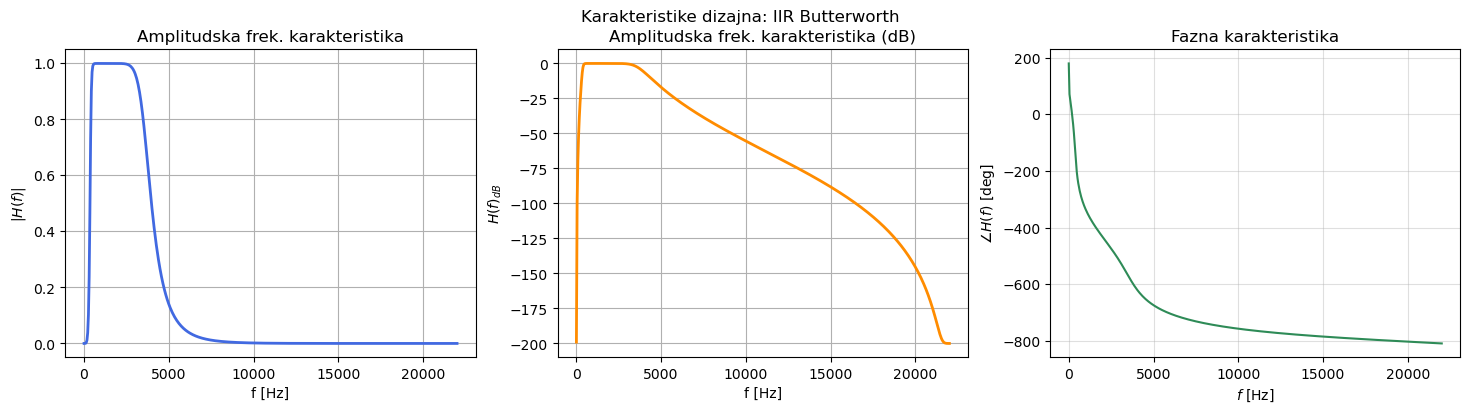

In [6]:
# Za IIR Butterworth
fig1, ax1 = plt.subplots(1, 3, figsize=(18, 4))
plot_freqz_custom(b_but, a_but, fs, ax1)
plt.suptitle("Karakteristike dizajna: IIR Butterworth")

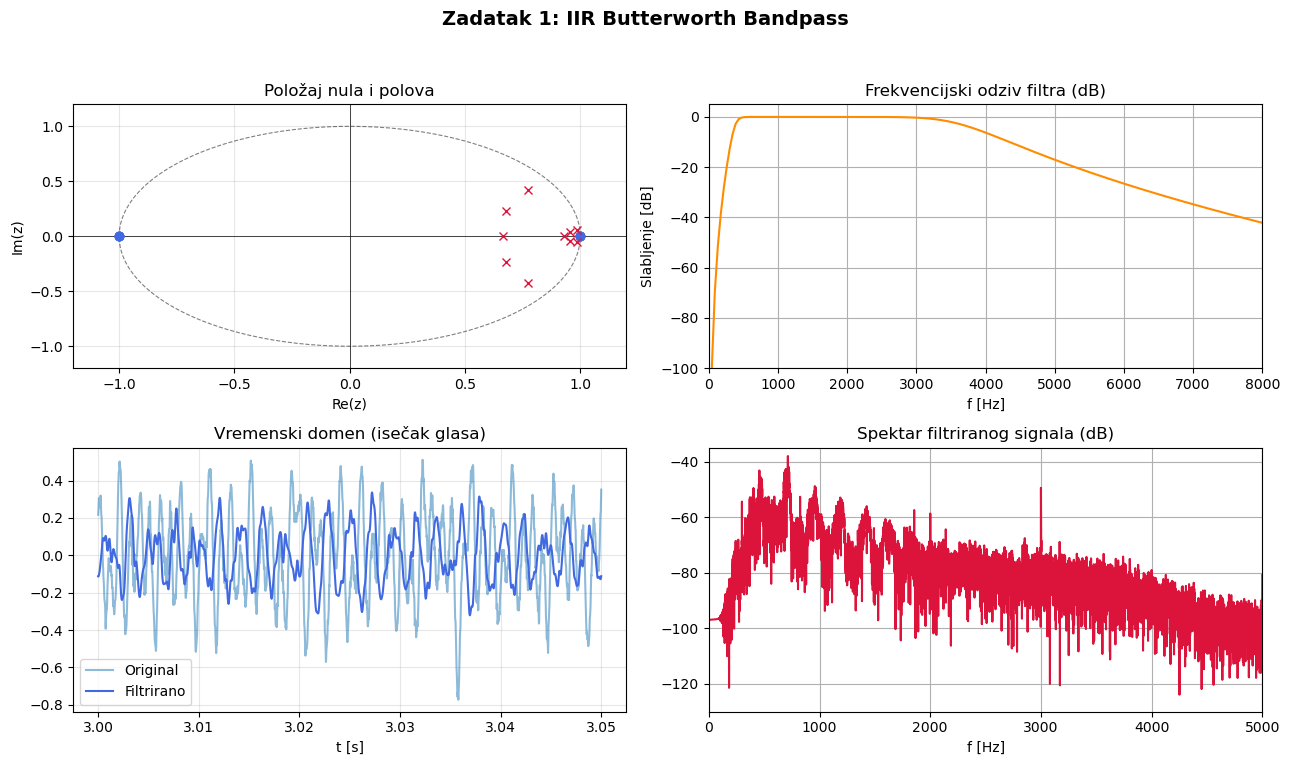

In [7]:
# Za IIR Butterworth
kompletna_analiza(b_but, a_but, y_iir1, "Zadatak 1: IIR Butterworth Bandpass")

Izabrala sam ga jer ne unosi talasanja u propusni opseg što je od velike važnosti za očuvanje prirodne boje glasa.   
#### Analiza karakteristika i grafika    
**- Položaj nula i polova (Z-ravan):**    
Vidim da se svi polovi (crveni iksići) nalaze unutar jediničnog kruga, što je potvrda da je ovaj sistem stabilan.
Primećuje se grupa polova koncentrisana blizu ugla koji odgovara propusnom opsegu, dok nule na jediničnom krugu obezbeđuju slabljenje na veoma niskim i visokim učestanostima.    
**- Frekvencijski odziv filtra (dB):**    
Narandžasta kriva pokazuje potpuno ravan vrh bez talasanja. Jasno se vidi blagi, ali kontinuirani pad ka opsezima koje izostavljamo.    
**- Vremenski domen (isečak glasa):**    
Upoređivanjem originala (svetloplava) i filtriranog signala (tamnoplava), vidi se značajna razlika. Original je prekriven gustim oscilacijama visoke frekvencije (šuštanje kese), dok je filtrirani signal gladak i prati govor.     
**- Spektar filtriranog signala (dB):**         
Ovo je ključni dokaz uspeha: na mestu gde je bio oštar šiljak na 1000 Hz, sada vidimo duboki usek (Notch). Smetnja je potisnuta daleko ispod nivoa korisnog signala.

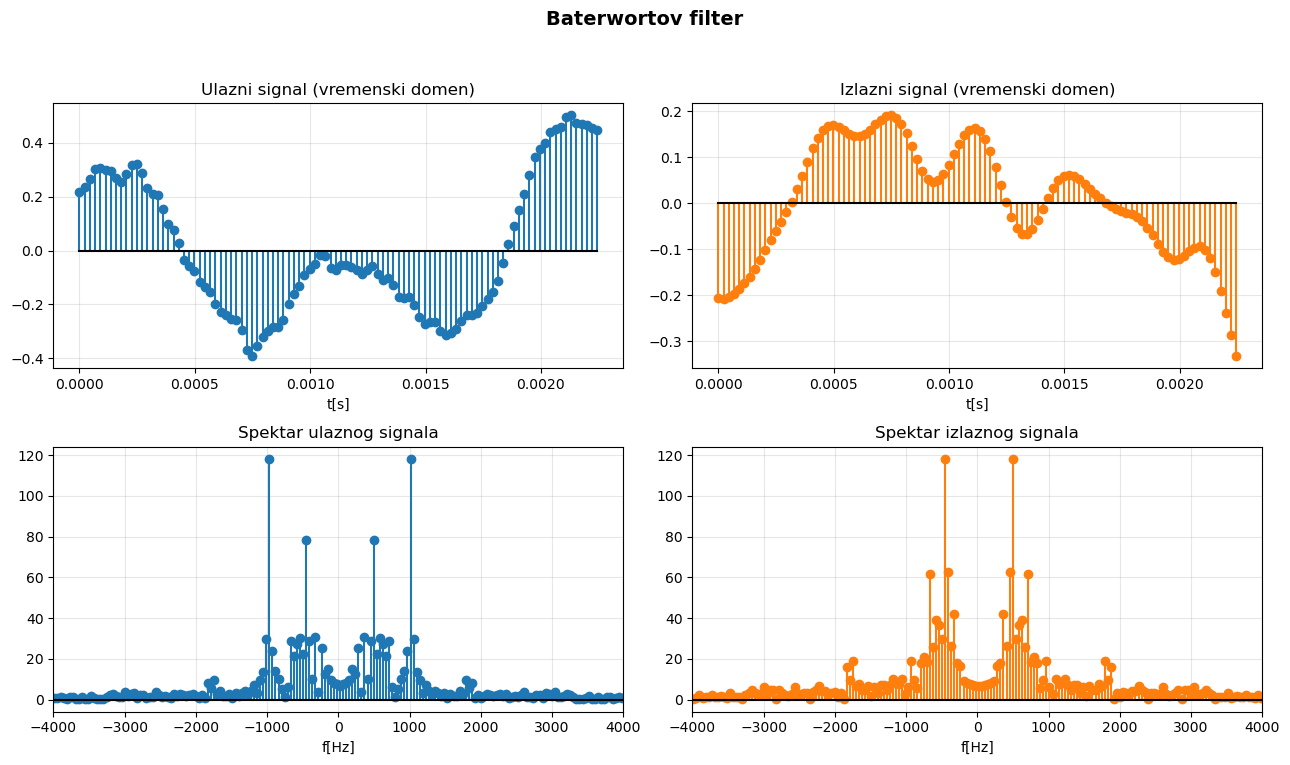

In [8]:
# Za IIR Butterworth
prikaz_vezba_stil(x, y_iir1, fs, "Baterwortov filter")

#### Analiza karakteristika i grafika    
Drugi set grafikona nam omogućava uvid u diskretnu prirodu signala.       
**- Vremenski domen:**    
Gornji grafici pokazuju koliko je dobro filter ispeglao signal. Levo vidimo ulazni signal koji je haotičniji/istrgan prikaz, a desno je izlazni signal koji je mnogo prirodniji.    
**- Spektar signala:**    
Posmatrajući donje grafike najuočljiviji je efekat Notch filtera. Primećujem da je oštar šiljak koji je na grafiku levo dominirao na 1000Hz, na grafiku desno potpuno eliminisan. Ostatak spektra koji nosi informaciju govora je ostao energetski očuvan.       
 
*Zaključak za ovaj filter:*              
IIR Butterworth u kombinaciji sa Notch filtrom je veoma efikasno uklonio sve tri vrste šuma. Glas je postao čist, a elektronsko pištanje je nečujno. Ipak, pošto je ovo IIR filtar, fazna karakteristika nije linearna.

Text(0.5, 0.98, 'Karakteristike dizajna: IIR Chebyshev II')

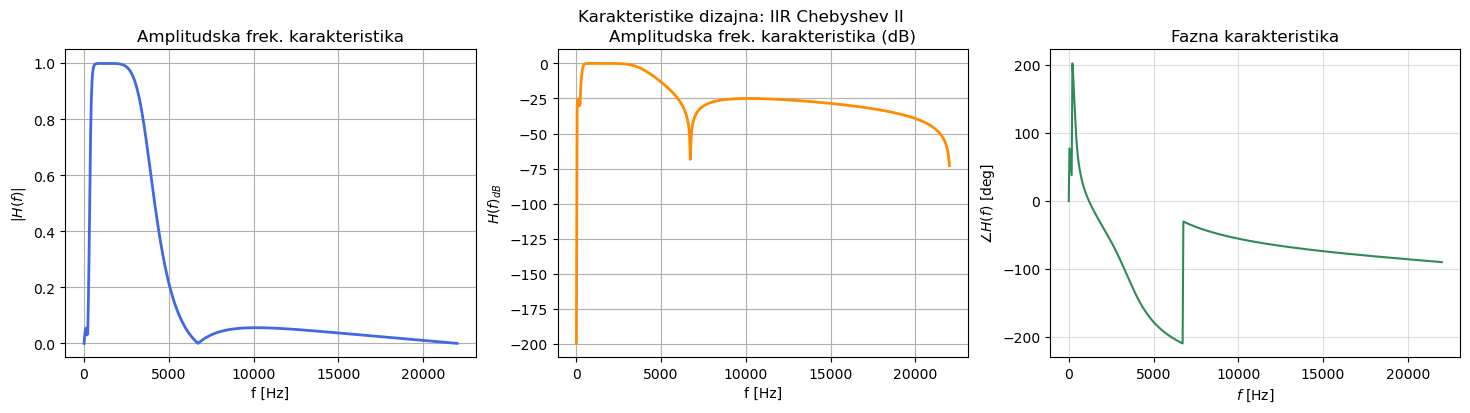

In [9]:
# Za IIR Chebyshev
fig2, ax2 = plt.subplots(1, 3, figsize=(18, 4))
plot_freqz_custom(b_cheb, a_cheb, fs, ax2)
plt.suptitle("Karakteristike dizajna: IIR Chebyshev II")

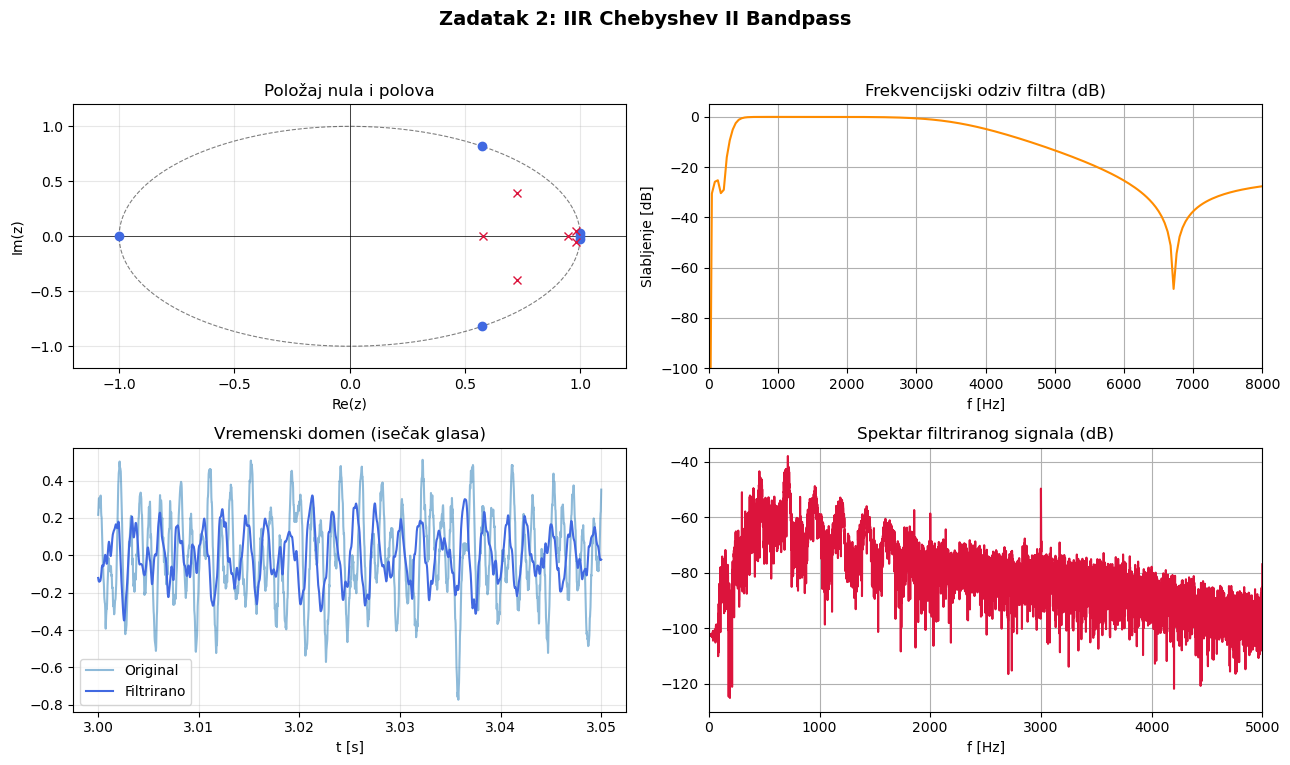

In [10]:
# Za IIR Chebyshev
kompletna_analiza(b_cheb, a_cheb, y_iir2, "Zadatak 2: IIR Chebyshev II Bandpass")

Nakon Butterwortha, projektovala sam sistem koristeći Chebyshev II. Glavni razlog za izbor ovog filtera jeste oštriji prelaz iz propusnog u nepropusni opseg.    
#### Analiza karakteristika i grafika    
**- Položaj nula i polova (Z-ravan):**    
Pored polova unutar kruga koji obezbeđuju stabilnost, vidim nule koje se nalaze direktno na jediničnoj kružnici. Ove nule su zaslužne za beskonačno slabljenje na specifičnim frekvencijama.   
**- Frekvencijski odziv filtra (dB):**    
Narandžasta kriva pokazuje ravan oblik u propusnom opsegu, a "ubod" vidimo na oko 6700Hz. To omogućava brže potiskivanje šuma kese na visokim frekvencijama.        
**- Vremenski domen (isečak glasa):**    
Rezultat je identičan Butterworhtu - glas dominira i oslobođen je šuma.    
**- Spektar filtriranog signala (dB):**         
Rezultat je identičan Butterworhtu - smetnja je potisnuta daleko ispod nivoa korisnog signala.

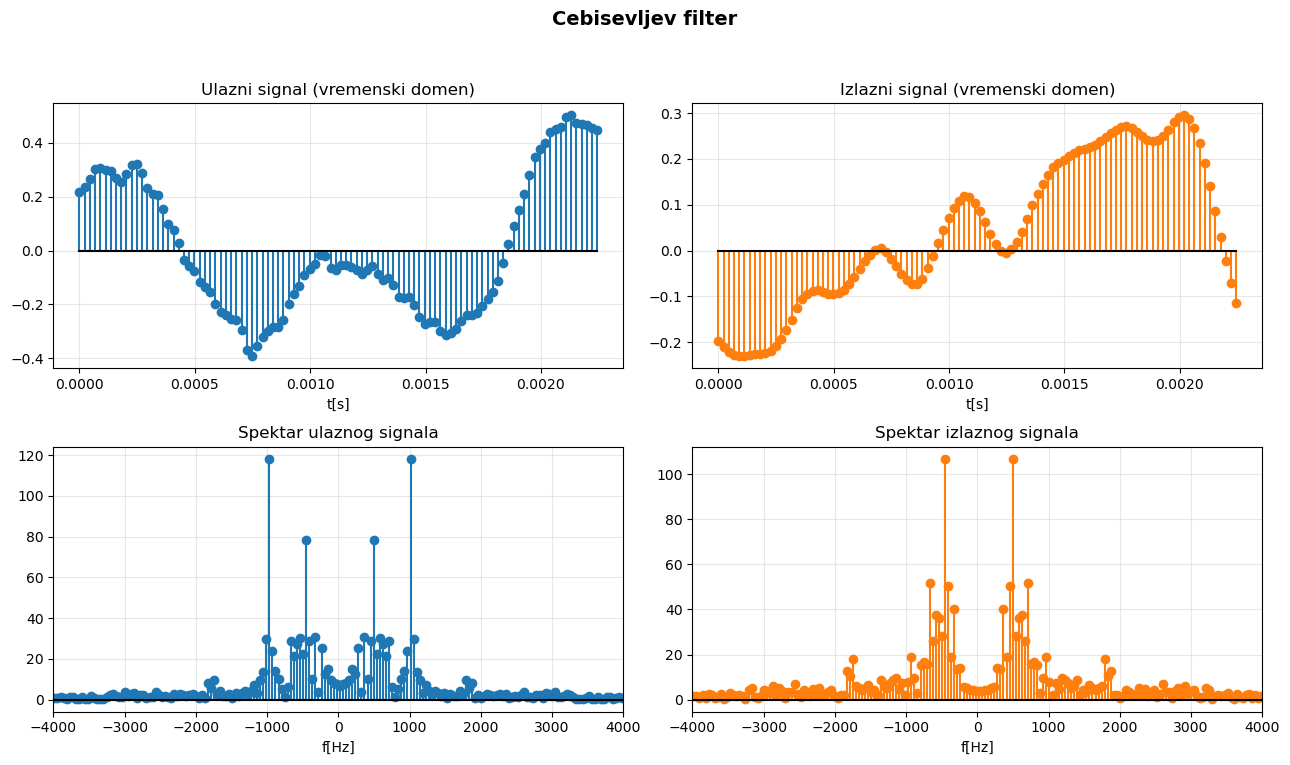

In [11]:
# Za IIR Chebyshev
prikaz_vezba_stil(x, y_iir2, fs, "Cebisevljev filter")

#### Analiza karakteristika i grafika    
Drugi set grafikona nam omogućava uvid u diskretnu prirodu signala.       
**- Vremenski domen:**    
Gornji grafici pokazuju koliko je dobro filter ispeglao signal. Desno je izlazni signal koji je mnogo prirodniji od ulaznog bez naglih skokova koji su prisutni levo.               
**- Spektar signala:**    
Primećujem da je oštar šiljak koji je na grafiku levo dominirao na 1000Hz, na grafiku desno potpuno eliminisan, a komponente glasa oko 500Hz su ostale snažne. 
 
*Zaključak za ovaj filter:*              
Iako oba filtra odlično obavljaju posao, Čebišev II teorijski nudi bolji kompromis: dobijamo oštriji rez na ivici govornog opsega (oko 3.5 kHz) uz zadržavanje savršeno ravnog odziva tamo gde je moj glas najbitniji. Ovo je ključni argument za korišćenje ove aproksimacije u audio obradi.

#### Projektovanje FIR filtera

In [12]:
# --- 4. FIR FILTRIRANJE

# Filter 3: FIR Bandpass (Hamming prozor)
N_fir1 = 101 # Red filtera
M1 = (N_fir1 - 1) // 2 # Grupno kašnjenje
h_fir1 = firwin(N_fir1, [300, 3400], pass_zero=False, window='hamming', fs=fs)

# Filter 4: FIR Bandpass (Hann prozor)
N_fir2 = 61
M2 = (N_fir2 - 1) // 2
fc_fir = [(300 + 150)/2, (3400 + 4500)/2] 
h_fir2 = firwin(N_fir2, fc_fir, pass_zero=False, window='hann', fs=fs)

# Primena
y_temp1 = lfilter(h_fir1, [1.0], x)
# Kompenzacija: sečemo prvih M1 odbiraka i dodajemo nule na kraj da dužina ostane ista
y_fir1_comp = np.append(y_temp1[M1:], np.zeros(M1))
y_fir1_final = lfilter(b_n, a_n, y_fir1_comp)      # Uklanjanje tona od 1000Hz

y_temp2 = lfilter(h_fir2, [1.0], x)
# Kompenzacija:
y_fir2_comp = np.append(y_temp2[M2:], np.zeros(M2))
y_fir2_final = lfilter(b_n, a_n, y_fir2_comp)      # Uklanjanje tona od 1000Hz


#### Pozivanje analize za svaki filter

Text(0.5, 0.98, 'Karakteristike dizajna: FIR Hamming')

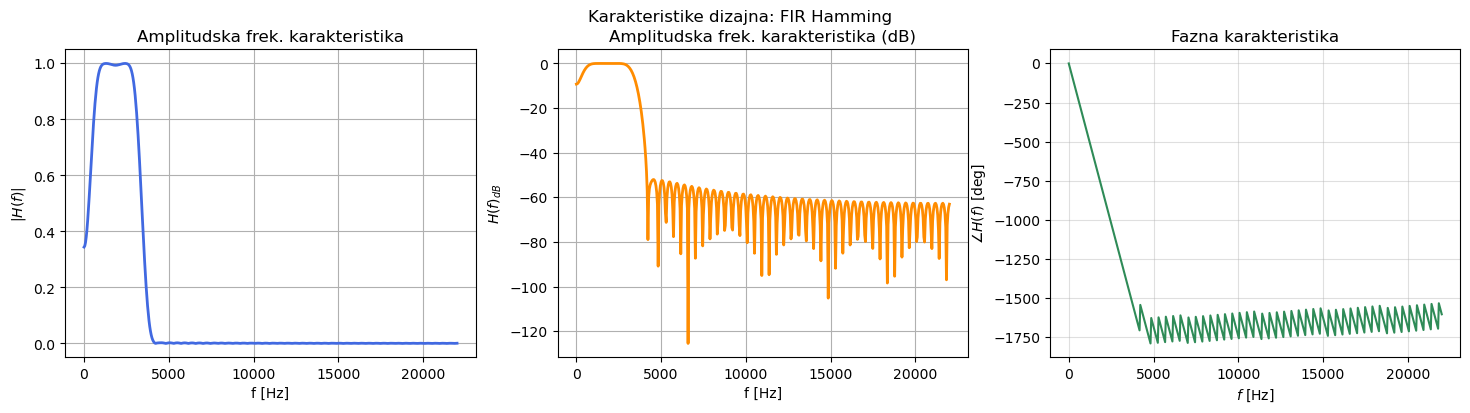

In [13]:
# Za FIR Hamming
fig3, ax3 = plt.subplots(1, 3, figsize=(18, 4))
plot_freqz_custom(h_fir1, [1.0], fs, ax3)
plt.suptitle("Karakteristike dizajna: FIR Hamming")

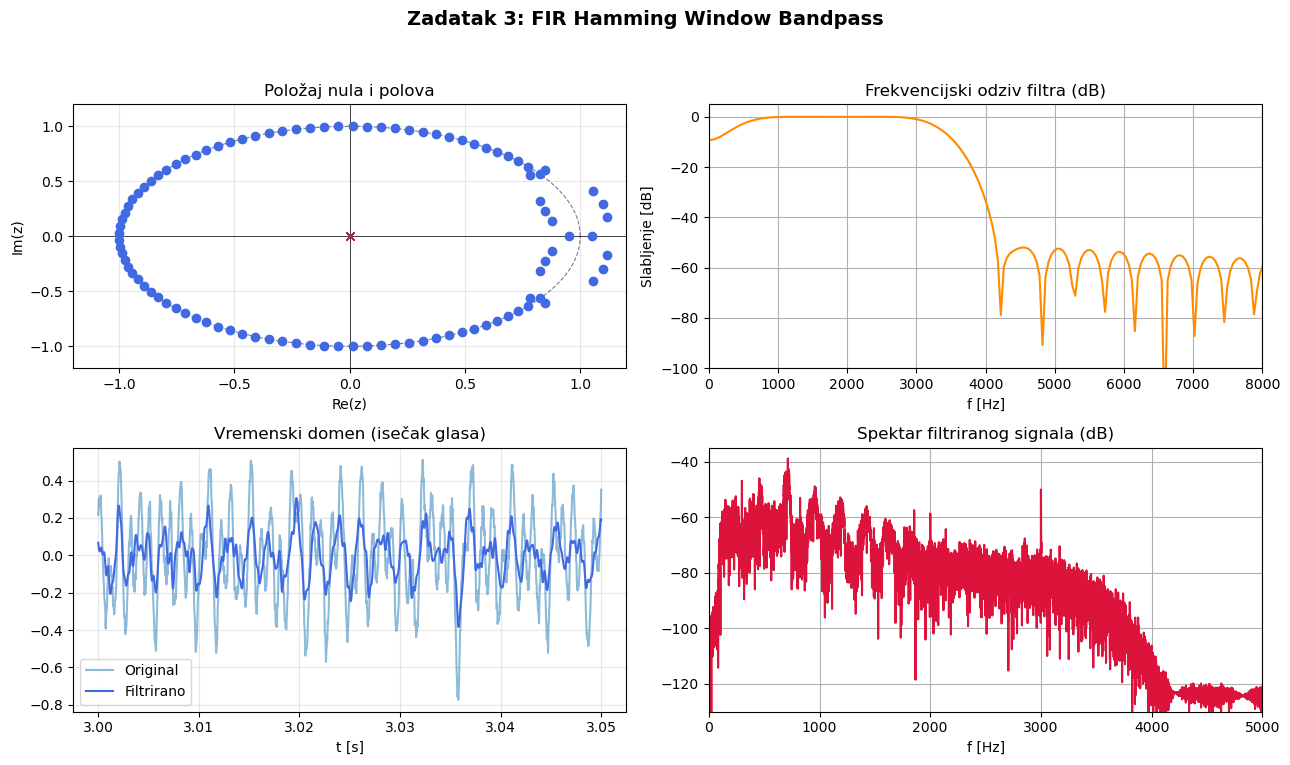

In [14]:
# Za FIR Hamming
kompletna_analiza(h_fir1, [1.0], y_fir1_final, "Zadatak 3: FIR Hamming Window Bandpass")

Glavna motivacija za koršćenje FIR filtera je linearna fazna karakteristika. U audio obradi ovo znači da sve frekvencijske komponente mog glasa prolaze kroz filtar sa identičnim vremenskim kašnjenjem, čime se izbegava fazno izobličenje koje može promeniti karakter vokala. 
#### Analiza karakteristika i grafika    
**- Položaj nula i polova (Z-ravan):**    
Svi polovi se nalaze tačno u koordinatnom početku. Veliki broj nula je raspoređen oko jediničnog kruga što znači da formiraju zaustavni opseg.   
**- Frekvencijski odziv filtra (dB):**    
Narandžasta kriva pokazuje potpuno ravan vrh bez talasanja. U zaustavnom opsegu vidim karakteristčne bočne talase.           
**- Vremenski domen (isečak glasa):**    
Plava i siva linija su savršeno poravnate jer sam primenila kompenzaciju grupnog kašnjenja. Filtriran signal je očišćen od šuma i prati prirodu glasa.      
**- Spektar filtriranog signala (dB):**         
Vidimo uspešnost!

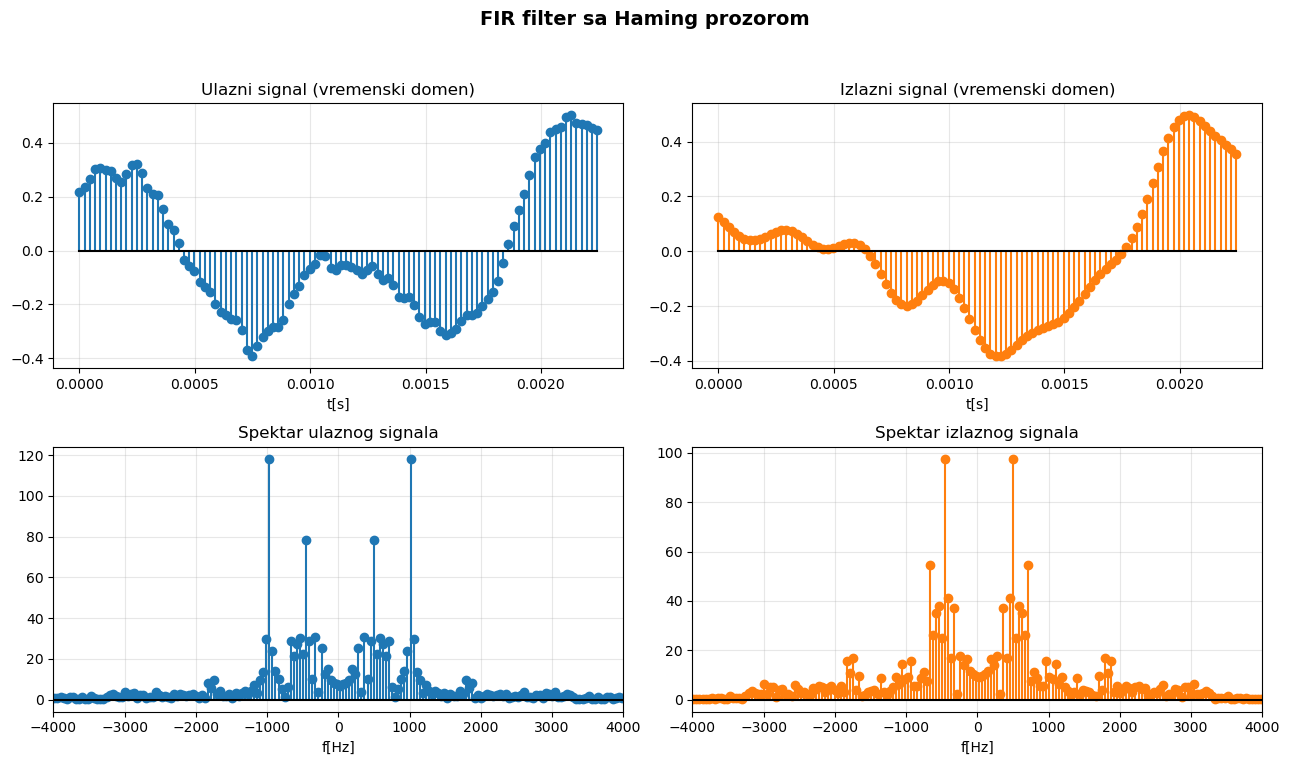

In [15]:
# Za FIR Hamming
prikaz_vezba_stil(x, y_fir1_final, fs, "FIR filter sa Haming prozorom")

#### Analiza karakteristika i grafika    
Drugi set grafikona nam omogućava uvid u diskretnu prirodu signala.       
**- Vremenski domen:**    
Gornji grafici pokazuju koliko je dobro filter ispeglao signal. Levo vidimo ulazni signal koji je haotičniji/istrgan prikaz, a desno je izlazni signal koji je mnogo prirodniji. Važno je uočiti da narandžasti odbirci počinju tačno u isto vreme kada i plavi. Ovo je vizuelni dokaz uspešno izvršene kompenzacije grupnog kašnjenja.     
**- Spektar signala:**    
Posmatrajući donje grafike najuočljiviji je efekat Notch filtera. Primećujem da je oštar šiljak koji je na grafiku levo dominirao na 1000Hz, na grafiku desno potpuno eliminisan. Ostatak spektra koji nosi informaciju govora je ostao energetski očuvan.       
 
*Zaključak za ovaj filter:*              
FIR Hamming filtar nudi vrhunski kvalitet zvuka. Iako je računarski zahtevniji (zahteva red 101 naspram IIR reda 8 ili 10), očuvanje faze čini glas prirodnijim. Ovaj filtar je odličan balans između složenosti i performansi. 

Text(0.5, 0.98, 'Karakteristike dizajna: FIR Hann')

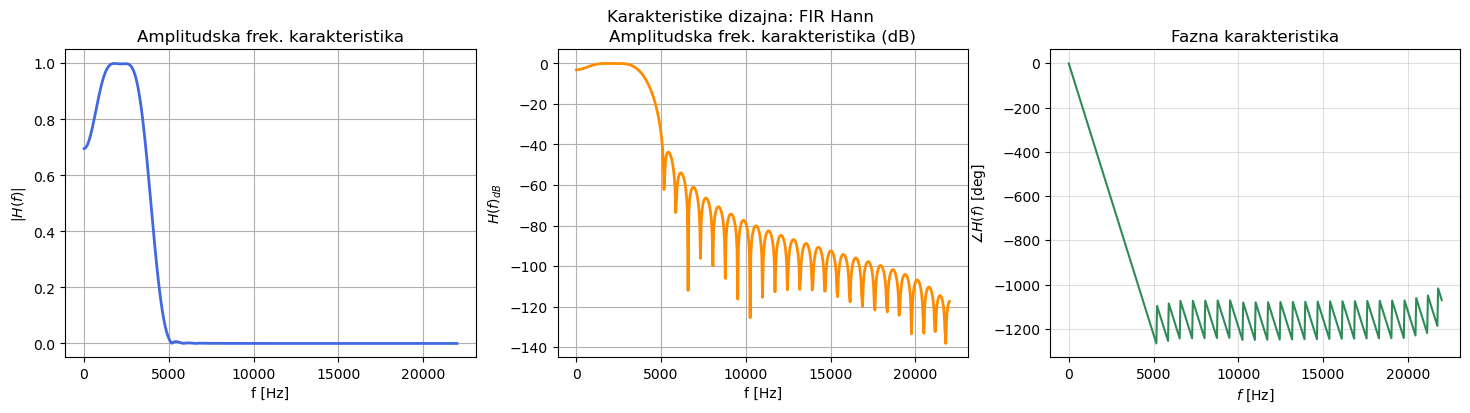

In [16]:
# Za FIR Hann 
fig4, ax4 = plt.subplots(1, 3, figsize=(18, 4))
plot_freqz_custom(h_fir2, [1.0], fs, ax4)
plt.suptitle("Karakteristike dizajna: FIR Hann")

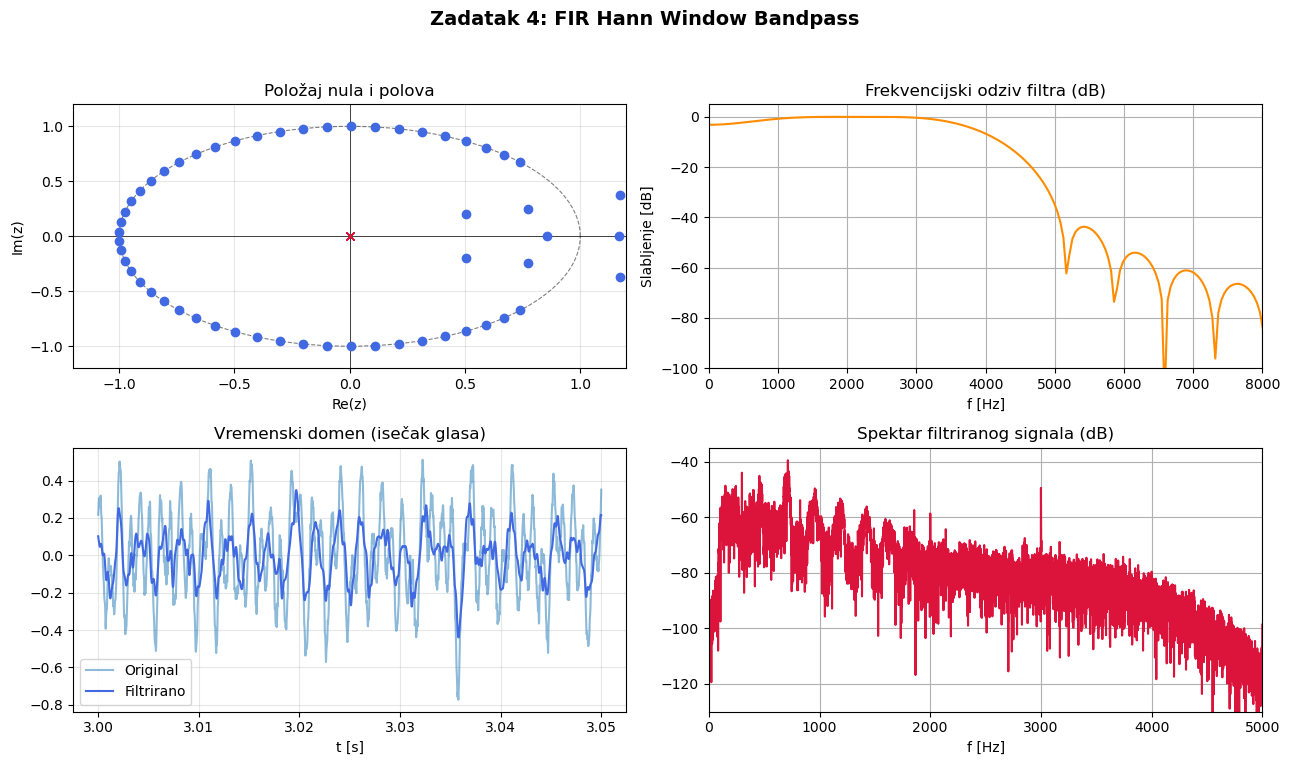

In [17]:
# Za FIR Hann 
kompletna_analiza(h_fir2, [1.0], y_fir2_final, "Zadatak 4: FIR Hann Window Bandpass")

Iako su Hamming i Hann prozor slični, Hanov prozor sam izabrala zbog karakteristike bržeg opadanja bočnih lukova. Mnogo brže guši frekvencije kako se udaljava od propusnog opsega. 
#### Analiza karakteristika i grafika    
**- Položaj nula i polova (Z-ravan):**    
Svi polovi se nalaze tačno u koordinatnom početku. Veliki broj nula je raspoređen oko jediničnog kruga što znači da formiraju zaustavni opseg.   
**- Frekvencijski odziv filtra (dB):**    
Narandžasta kriva pokazuje potpuno ravan vrh bez talasanja. U zaustavnom opsegu vidim karakteristčne bočne talase koji desno od 5000Hz opadaju naglo i dostižu vrednost ispod -80dB.                  
**- Vremenski domen (isečak glasa):**    
Plava i siva linija su savršeno poravnate jer sam primenila kompenzaciju grupnog kašnjenja. Filtriran signal je očišćen od šuma i prati prirodu glasa.      
**- Spektar filtriranog signala (dB):**         
Vidimo uspešnost!

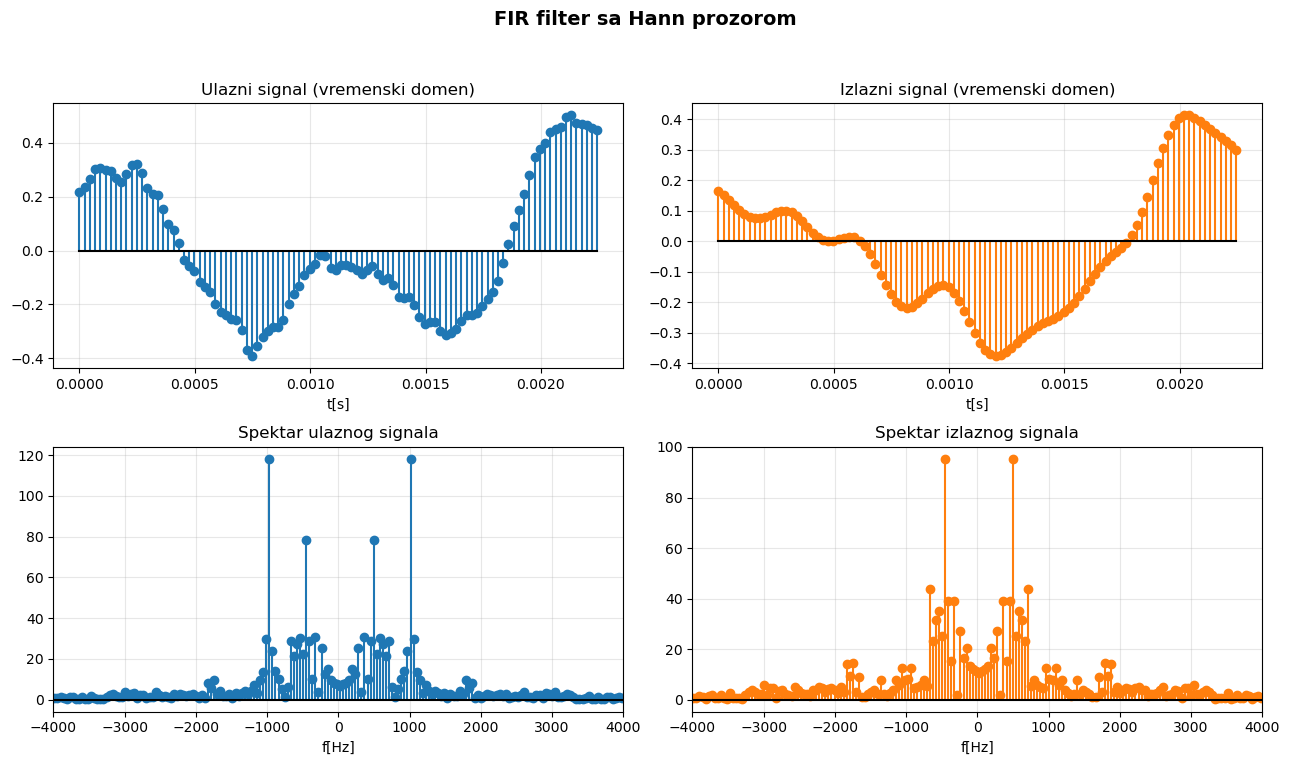

In [18]:
# Za FIR Hann 
prikaz_vezba_stil(x, y_fir2_final, fs, "FIR filter sa Hann prozorom")

#### Analiza karakteristika i grafika    
Drugi set grafikona nam omogućava uvid u diskretnu prirodu signala.       
**- Vremenski domen:**    
Isto kao i prethodni.    
**- Spektar signala:**    
Isto kao i prethodni.       
 
*Zaključak za ovaj filter:*              
Filter sa Hanovim prozorom daje za nijansu prirodniji zvuk od Hemingovog, upravo zbog boljeg potiskivanja vrlo visokih učestanosti šuma kese. S obzirom na linearnu fazu ovaj sistem je jedan od najjačih kandidata za finalno rešenje.

#### Prikaz i snimanje rezultata

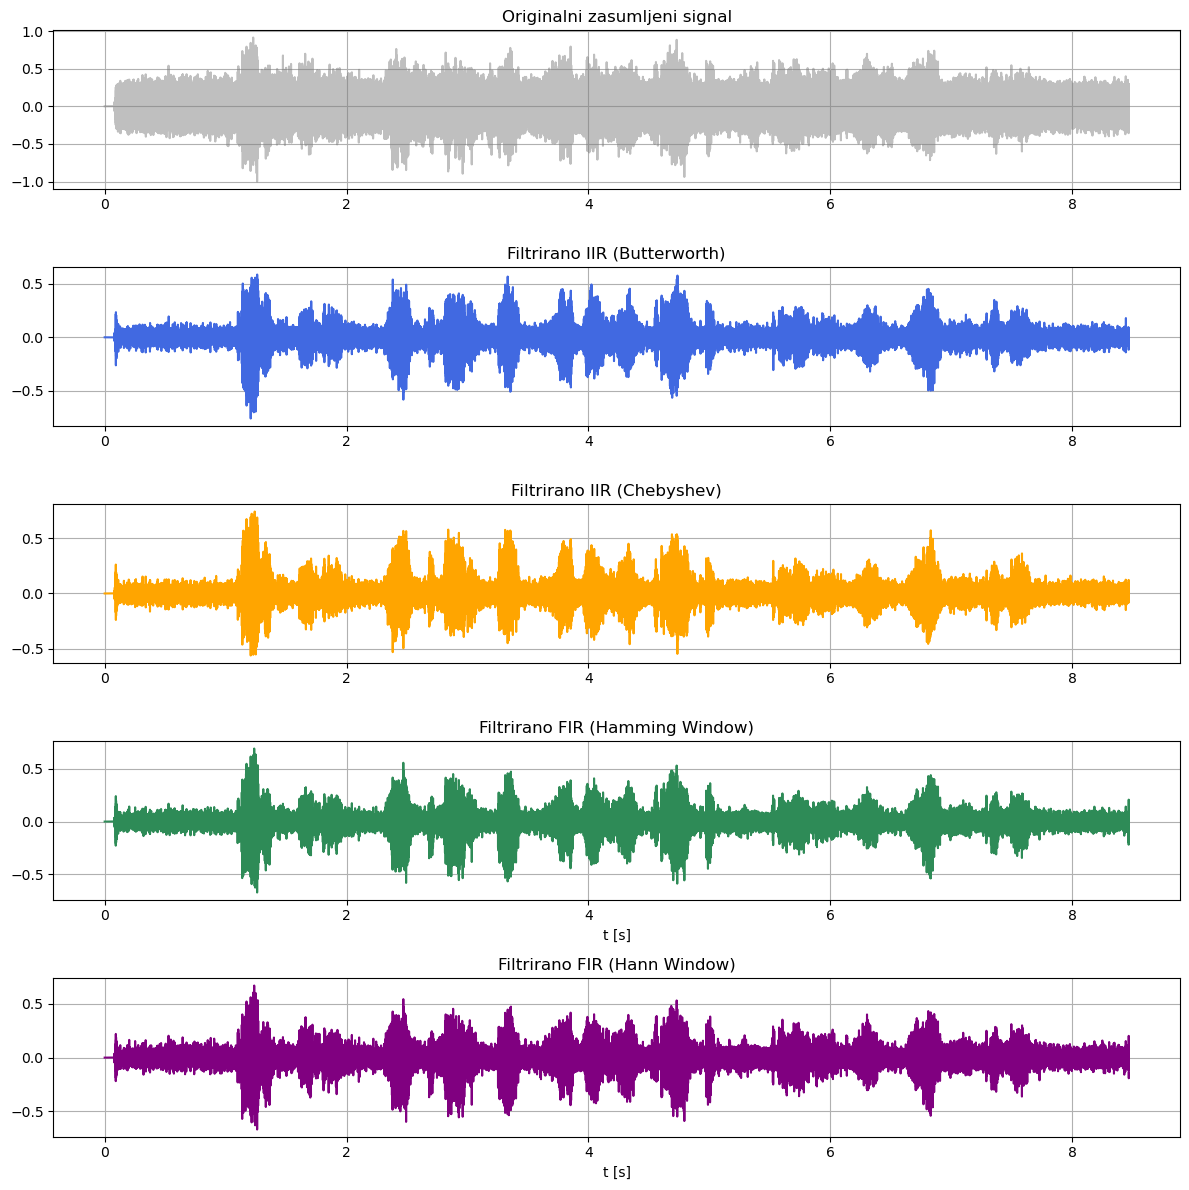

SVI AUDIO FAJLOVI SU USPEŠNO SAČUVANI!!


In [19]:

plt.figure(figsize=(12, 12))
plt.subplot(5, 1, 1)
plt.plot(vreme, x, color='gray', alpha=0.5)
plt.title('Originalni zasumljeni signal')
plt.grid()

plt.subplot(5, 1, 2)
plt.plot(vreme, y_iir1, color='royalblue')
plt.title('Filtrirano IIR (Butterworth)')
plt.grid()

plt.subplot(5, 1, 3)
plt.plot(vreme, y_iir2, color='orange')
plt.title('Filtrirano IIR (Chebyshev)')
plt.grid()

plt.subplot(5, 1, 4)
plt.plot(vreme, y_fir1_final, color='seagreen')
plt.title('Filtrirano FIR (Hamming Window)')
plt.xlabel('t [s]')
plt.grid()

plt.subplot(5, 1, 5)
plt.plot(vreme, y_fir2_final, color='purple')
plt.title('Filtrirano FIR (Hann Window)')
plt.xlabel('t [s]')
plt.grid()

plt.tight_layout()
plt.show()

# 1. Snimanje rezultata IIR Butterworth + Notch
wavfile.write('Rezultat_1_IIR_Butterworth.wav', fs, (y_iir1 * 32767).astype(np.int16))

# 2. Snimanje rezultata IIR Chebyshev II + Notch
wavfile.write('Rezultat_2_IIR_Chebyshev.wav', fs, (y_iir2 * 32767).astype(np.int16))

# 3. Snimanje rezultata FIR Hamming + Notch
wavfile.write('Rezultat_3_FIR_Hamming.wav', fs, (y_fir1_final * 32767).astype(np.int16))

# 4. Snimanje rezultata FIR Hann + Notch
wavfile.write('Rezultat_4_FIR_Hann.wav', fs, (y_fir2_final * 32767).astype(np.int16))

print("SVI AUDIO FAJLOVI SU USPEŠNO SAČUVANI!!")

#### Zaključak  
Butterworth je zahtevao veći red (oko 10) da bi zadovoljio gabarit, dok je Chebyshev II isti rezultat postigao sa nižim redom (oko 8). Oba filtera imaju ravnu karakteristiku u propusnom opsegu, pa je boja glasa očuvana. Međutim, zbog nelinearne faze, glas subjektivno može zazvučati blago „metalno” naročito kod Butterwortha. Chebyshev II se bolje pokazao u odsecanju šuma, a i glas je ostao prirodniji, međutim očuvanje glasa nosi sa sobom posledice. Odlično je očuvao glas S i C ali samim tim prisutan je zvuk šuštanja kese. 
Najveća prednost FIR filtara je linearna faza. Hamming sa redom od 101 daje dobro slabljenje šuma, ali su njegovi bočni lukovi konstantne visine. Hann sa redom 61 ima osobinu da bočne lukove brzo smanji, tj da smanji njihovu frekvenciju. Generalno su dali bolji rezultat od IIR filtera jer su pažljivije očuvali glas.   
**Postignuta** je potpna eliminacija pištanja na 1000Hz i značajno je smanjeno šuštanje kese.        
**Izgubila** sam najdublje i najviše komponente glasa jer sam odsekla sve ispod 100Hz i iznad 3500Hz. To je bilo neophodno kkao bih uklonila visokofrekventni i niskofrekventi šum, pa sam eksperimentisanjem ostavila najbolju verziju. 

Radi lakše analize audio snimaka (prilikom slušanja), izdvojila sam signal bez piskavog tona.

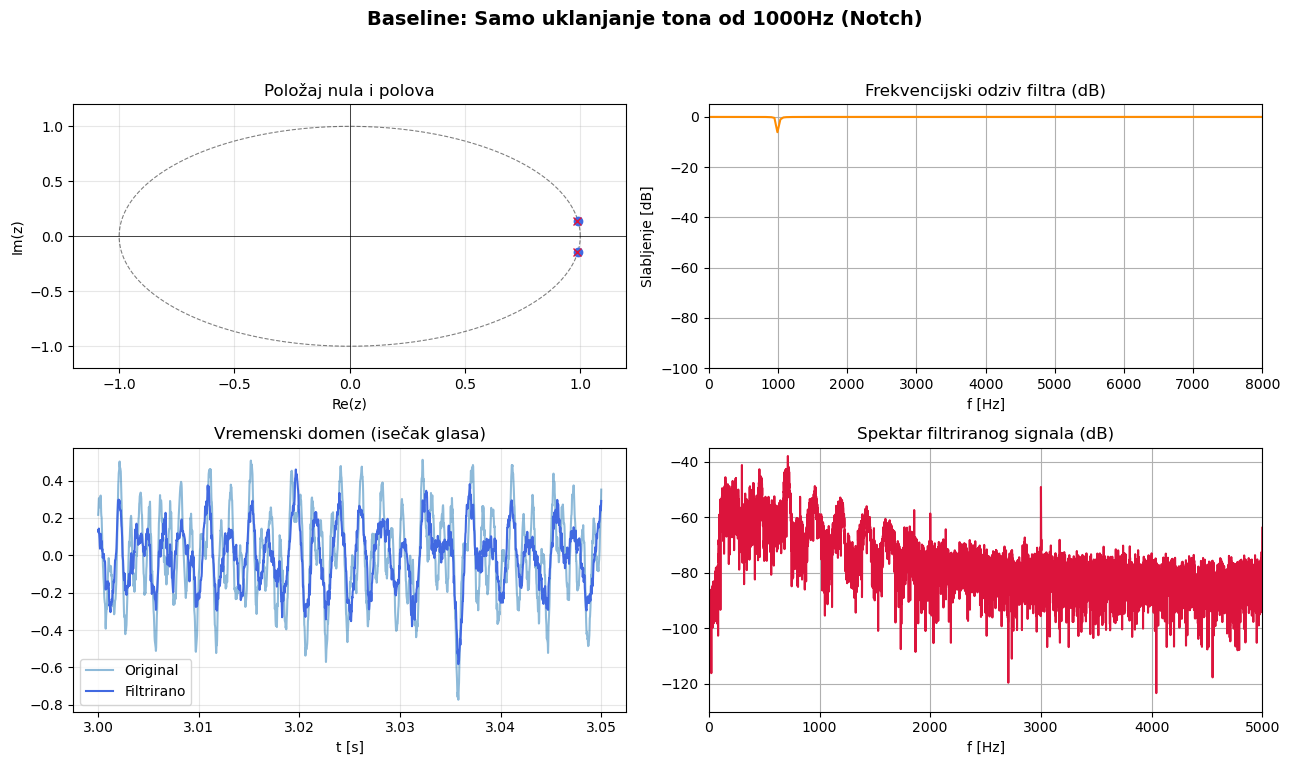

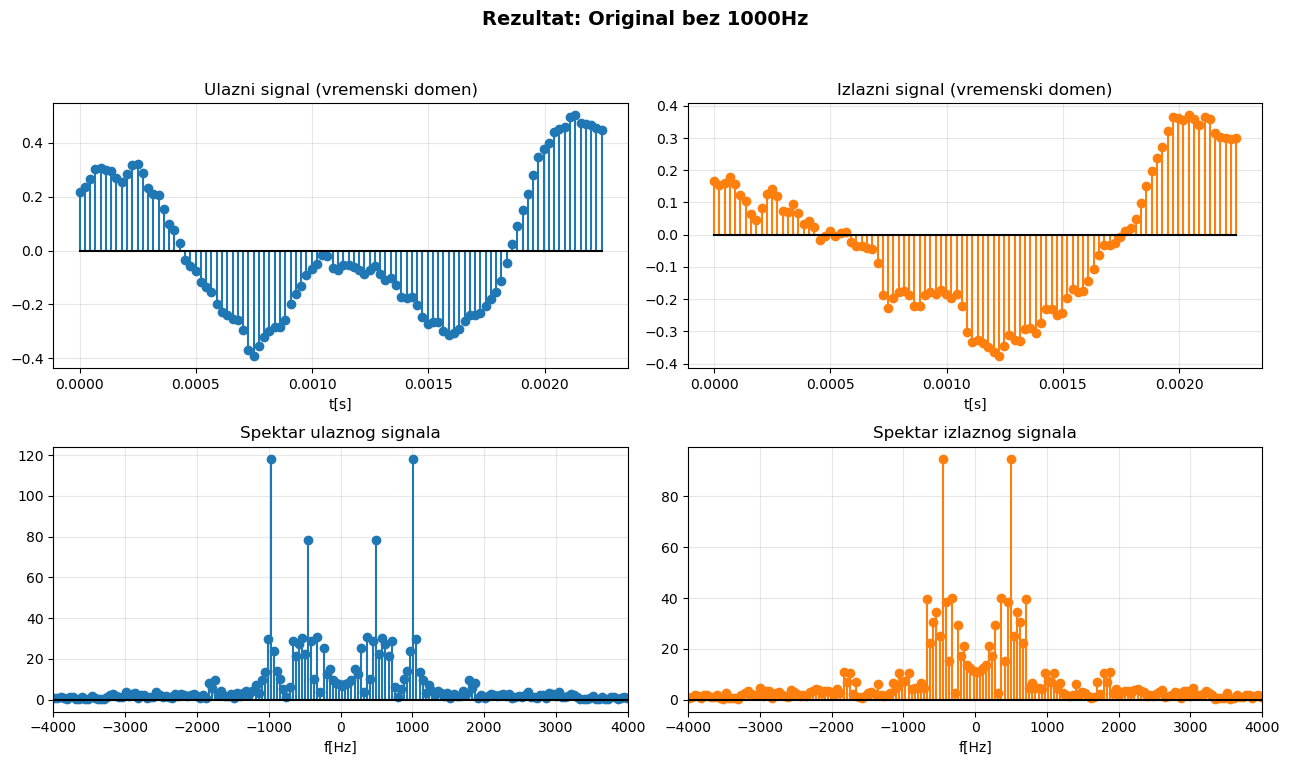

Završen prikaz signala bez 1000Hz.


In [20]:
# --- 0. ANALIZA: SAMO UKLANJANJE TONA OD 1000Hz (Notch) 

# Primenjujemo Notch filter direktno na originalni signal 'x'
# b_n i a_n su već definisani u kodu sa iirnotch(1000, 30, fs)
y_only_notch = lfilter(b_n, a_n, x)

# 1. Detaljna analiza (Z-ravan, dB, Vreme, Spektar)
kompletna_analiza(b_n, a_n, y_only_notch, "Baseline: Samo uklanjanje tona od 1000Hz (Notch)")

# 2. Prikaz u
prikaz_vezba_stil(x, y_only_notch, fs, "Rezultat: Original bez 1000Hz")

# 3. Snimanje fajla
wavfile.write('Original_bez_1000Hz.wav', fs, (y_only_notch * 32767).astype(np.int16))

print("Završen prikaz signala bez 1000Hz.")

### SISTEM FILTRIRANJA KOMBINACIJOM FILTARA

Nakon analize pojedinačnih filtera shvatila sam da svaki tip ima svoje prednosti i mane.   
S toga jedna od ideja bila je da iskombinujem primenjene filtere i vidim kakv ću rezultat dobiti. IIR Butterworth filter je iskorišten da se na 200Hz potpuno odseče brujanje uređaja. Od značaja je bila oštrina IIR filtera. FIR Hann filter je iskorišten za deo spektra gde se nalaze visoki harmonici glasa. Zahvaljujući njegovoj linearnoj fazi, glas je ostao poprilično prirodan i nije zvučao tupo i veštački. Naravno, pored toga koristila sam i Notch filter za precizno uklanjanje frekvencije od 1000Hz.        
Ključno što vidim na frekvencijskom odzivu je da imam oštar pad na niskim frekvencijama što je zasluga IIR filtra, a zatim brzo opadanje bočnih lukova na visokim frekvencijama što je zasluga Hann FIR filtra.         
Signal je očišćen od sva tri tipa šuma, i glas je ostao što je više moguće prirodan.

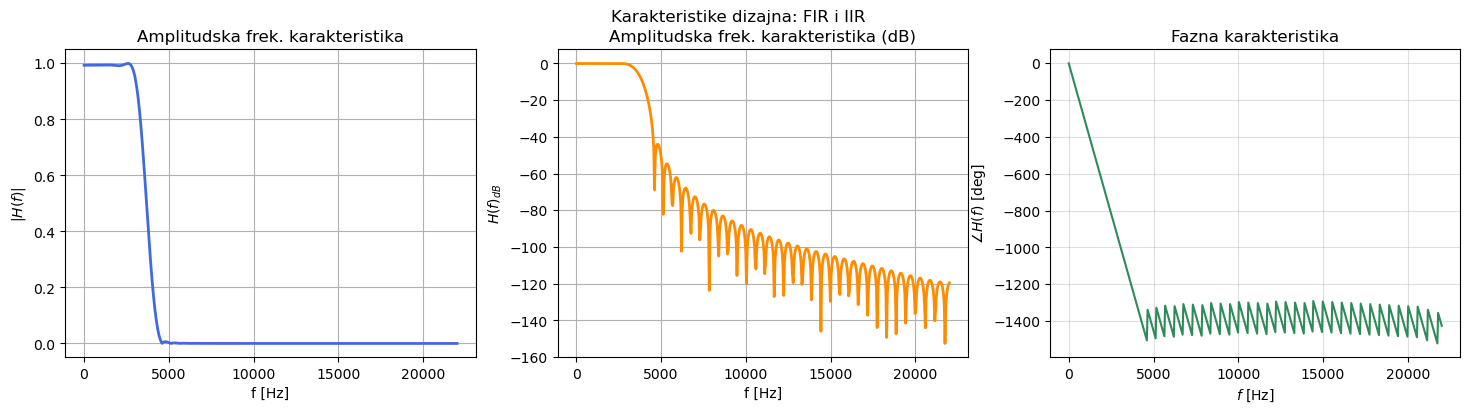

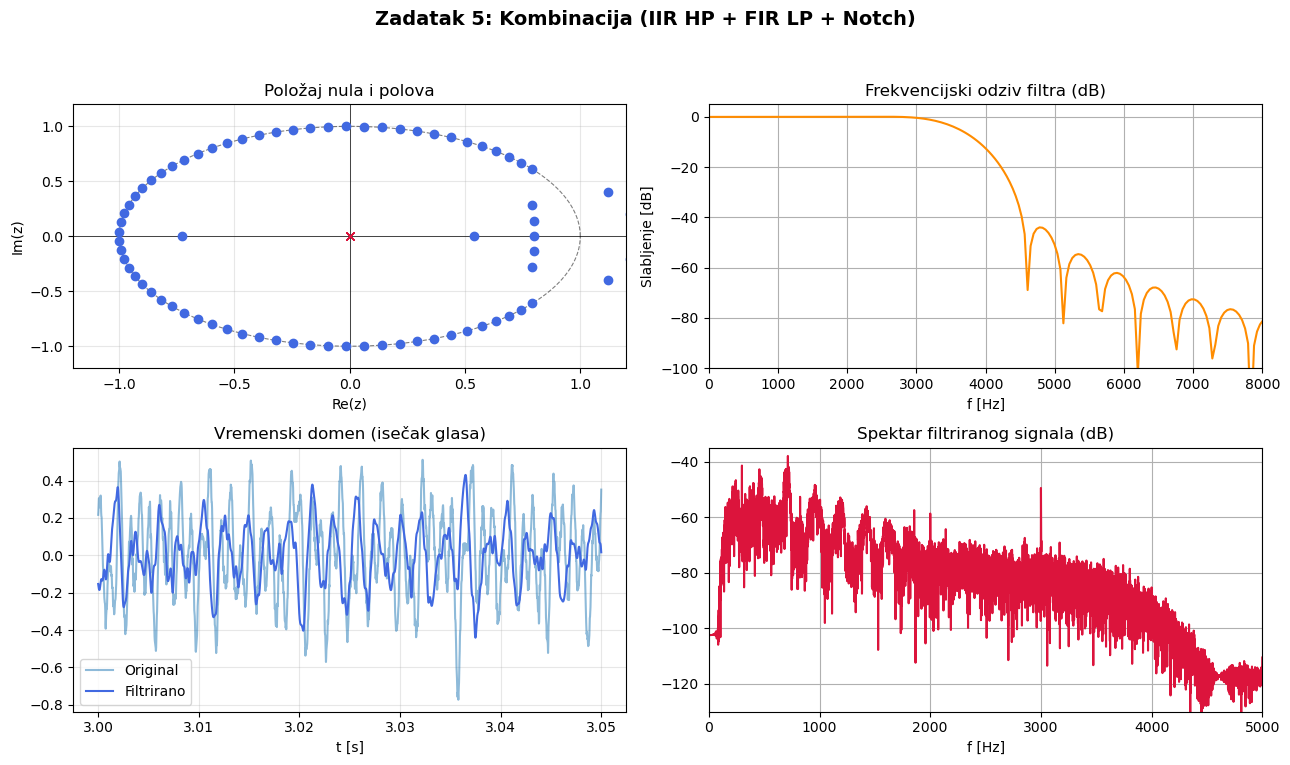

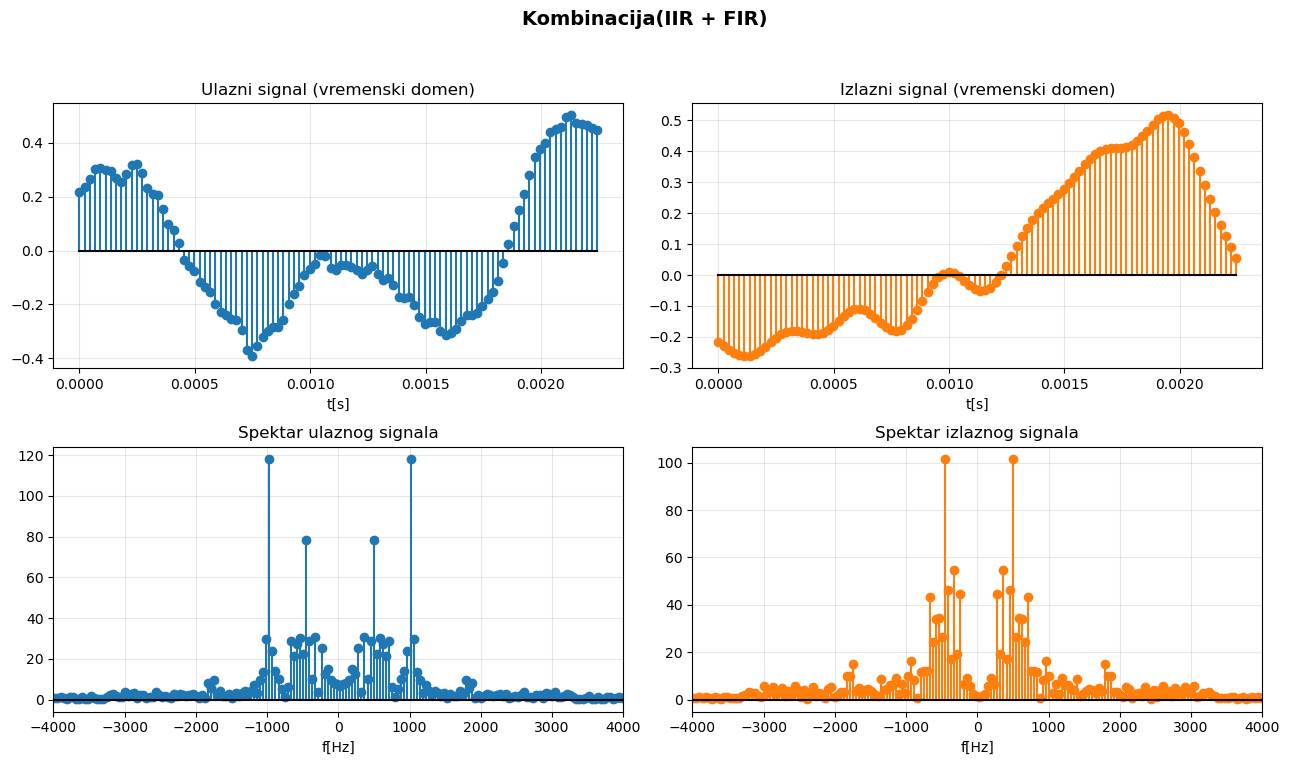

Uspešno je generisan!


In [21]:
# --- 7. ZADATAK 5: KOMBINACIJA(IIR + FIR + Notch)

# KORAK 1: IIR High-pass (za oštro uklanjanje niskofrekventnog brujanja)
# Koristimo Butterworth 4. reda
b_hp, a_hp = butter(4, 200 / f_nyq, btype='highpass')
y_stage1 = lfilter(b_hp, a_hp, x)

# KORAK 2: FIR Low-pass (za prirodno uklanjanje šuštanja kese)
N_hybrid = 81
h_lp = firwin(N_hybrid, 3690 / f_nyq, window='hann')
M_h = (len(h_lp) - 1) // 2
y_stage2_tmp = lfilter(h_lp, [1.0], y_stage1)
y_stage2 = np.append(y_stage2_tmp[M_h:], np.zeros(M_h)) # Kompenzacija kašnjenja

# KORAK 3: IIR Notch (za uklanjanje pištanja na 1000Hz)
b_n, a_n = iirnotch(1000, 60, fs)
y_hybrid_final = lfilter(b_n, a_n, y_stage2)

# --- PRIKAZ REZULTATA 
# Detaljna analiza (Z-ravan, dB, Vreme, Spektar)
# Za b i a parametre šaljemo FIR koeficijente jer su oni dominantni za fazu
fig5, ax5 = plt.subplots(1, 3, figsize=(18, 4))
plot_freqz_custom(h_lp, [1.0], fs, ax5)
plt.suptitle("Karakteristike dizajna: FIR i IIR ")

kompletna_analiza(h_lp, [1.0], y_hybrid_final, "Zadatak 5: Kombinacija (IIR HP + FIR LP + Notch)")

prikaz_vezba_stil(x, y_hybrid_final, fs, "Kombinacija(IIR + FIR)")

# Snimanje finalnog audio fajla
wavfile.write('Kombinacija.wav', fs, (y_hybrid_final * 32767).astype(np.int16))

print("Uspešno je generisan!")

### Analiza svih rezultata   
Na kraju sam odlučila da istražim na internetu najbolji način za analizu svih izlaza koje sam dobila. Cilj je bio da pronađem koji filter ili kombinacija filtera daje najbolji rezultat. 
Funkcija koju sam implementirala uzima filtriran signal i analizira njegovu spektralnu strukturu. Prvi deo proverava koliko je ostao glasan šum na 1000Hz. Drugi deo meri preostalu snagu šuštanja kese, i na izlazu dobijamo energiju tog opsega. Cilj jeste da energija bude što manja. Treći deo meri koliko je mog glasa uspešno očuvano, tačnije energiju korisnih frekvencija. Cilj je da ovaj broj bude što veći. Na kraju je SNR procena koja meri finalnu čistoću zvuka (kao odnos korisnog signala i snage šuma). Cilj je da ovaj broj bude što veći.

In [22]:
def analiziraj_kvalitet(y, x_orig, fs, ime):
    # 1. Magnituda na 1000Hz (Notch efikasnost)
    N = len(y)
    Y_fft = np.abs(np.fft.fft(y))
    indeks_1000 = int(1000 * N / fs)
    nivo_1000 = 20 * np.log10(Y_fft[indeks_1000] + 1e-12)
    
    # 2. Energija šuma iznad 4500Hz (Šuštanje kese)
    indeks_4500 = int(4500 * N / fs)
    energija_suma = np.sum(Y_fft[indeks_4500:N//2]**2)
    
    # 3. Energija govora (80Hz - 3800Hz)
    ind_low = int(80 * N / fs)
    ind_high = int(3800 * N / fs)
    energija_govora = np.sum(Y_fft[ind_low:ind_high]**2)
    
    # 4. Odnos Signal/Šum (procena na osnovu energije govora i visokog šuma)
    snr_procena = 10 * np.log10(energija_govora / (energija_suma + 1e-12))
    
    return nivo_1000, snr_procena

# Liste rezultata za poređenje
rezultati_y = [y_iir1, y_iir2, y_fir1_final, y_fir2_final, y_hybrid_final]
imena_filtera = ["1. IIR Butterworth", "2. IIR Chebyshev II", "3. FIR Hamming", "4. FIR Hann", "5. Kombinacija"]

print("\n" + "="*60)
print(f"{'Filter':<25} | {'Notch 1000Hz [dB]':<15} | {'SNR Procena [dB]':<12}")
print("-" * 60)

za_grafik_snr = []
za_grafik_notch = []

for y_rez, ime in zip(rezultati_y, imena_filtera):
    nivo, snr = analiziraj_kvalitet(y_rez, x, fs, ime)
    print(f"{ime:<25} | {nivo:<15.2f} | {snr:<12.2f}")
    za_grafik_notch.append(nivo)
    za_grafik_snr.append(snr)

print("="*60)
print("TUMAČENJE: Što je niži Notch dB (npr. -40 je bolje nego -10), ton od 1000Hz je tiši.")
print("TUMAČENJE: Što je veća SNR Procena, glas je čistiji u odnosu na šuštanje kese.")


Filter                    | Notch 1000Hz [dB] | SNR Procena [dB]
------------------------------------------------------------
1. IIR Butterworth        | 33.85           | 40.89       
2. IIR Chebyshev II       | 33.95           | 35.49       
3. FIR Hamming            | 34.31           | 47.48       
4. FIR Hann               | 33.48           | 47.22       
5. Kombinacija            | 40.19           | 61.31       
TUMAČENJE: Što je niži Notch dB (npr. -40 je bolje nego -10), ton od 1000Hz je tiši.
TUMAČENJE: Što je veća SNR Procena, glas je čistiji u odnosu na šuštanje kese.


Objektivnom procenom je utvrđeno da kombinacija FIR i IIR filtera pruža najveći SNR od 61.31dB što upravo znači da je najbolji u eliminisanju šumova koje sam imala!